# This script is for analysing the experimental data of both muscles and doing some comparisons

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import seaborn as sns
import math
from scipy import signal
import seaborn as sns
import seaborn as sns
import h5py
from scipy.stats import zscore
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
from scipy.stats import ks_2samp
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.svm import SVR
from sklearn.model_selection import cross_val_score, KFold


## Experimental distribution neuron per neuron

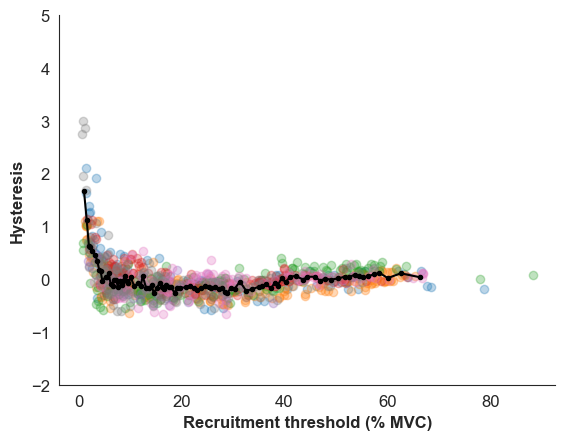

In [2]:
sns.set_style("white")
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12

def process_data(file_path):
    df = pd.read_csv(file_path)
    df = df.dropna(how='all')
    df['hysteresis'] = df.iloc[:, 1] / df.iloc[:, 0] - 1
    df['zscore'] = zscore(df['hysteresis'])
    return df[df['zscore'].abs() <= 3] 

# df1 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S1.csv')
# df2 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S2.csv')
# df3 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S3.csv')
# df4 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S4.csv')
# df5 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S5_.csv')
# df6 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S6.csv')
# df7 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S7.csv')
# df8 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S8.csv')

df1 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S1KE.csv')
df2 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S2KE.csv')
df3 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S3KE.csv')
df4 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S4KE.csv')
df5 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S5KE.csv')
df6 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S6KE.csv')
df7 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S7KE.csv')
df8 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S8KE.csv')

all_values_hysteresis=np.concatenate([df["hysteresis"] for df in [df1, df2, df3, df4, df5, df6, df7, df8]])
all_values_recr= np.concatenate([df.iloc[:, 0] for df in [df1, df2, df3, df4, df5, df6, df7, df8]])

combined_df = pd.DataFrame({ 'force': all_values_recr,'hysteresis': all_values_hysteresis})
sorted_df = combined_df.sort_values(by='force')

vals=np.array(sorted_df['hysteresis'])
vals_force=np.array(sorted_df['force'])

d=10

binned_hyst = [np.mean(vals[i:i+d]) for i in range(0, len(vals), d) if i+d <= len(vals)]
binned_hyst_var = [np.var(vals[i:i+d]) for i in range(0, len(vals), d) if i+d <= len(vals)]

binned_force = [np.mean(vals_force[i:i+d]) for i in range(0, len(vals_force), d) if i+d <= len(vals_force)]


plt.scatter(df1.iloc[:, 0], df1['hysteresis'], alpha=0.3, label='S1')
plt.scatter(df2.iloc[:, 0], df2['hysteresis'], alpha=0.3, label='S2')
plt.scatter(df3.iloc[:, 0], df3['hysteresis'], alpha=0.3, label='S3')
plt.scatter(df4.iloc[:, 0], df4['hysteresis'], alpha=0.3, label='S4')
plt.scatter(df5.iloc[:, 0], df5['hysteresis'], alpha=0.3, label='S5')
plt.scatter(df6.iloc[:, 0], df6['hysteresis'], alpha=0.3, label='S6')
plt.scatter(df7.iloc[:, 0], df7['hysteresis'], alpha=0.3, label='S7')
plt.scatter(df8.iloc[:, 0], df8['hysteresis'], alpha=0.3, label='S8')


plt.plot(binned_force,binned_hyst, '.-', color='black')#label='Evolving Mean')


#######
plt.ylim(-2, 5)
# plt.title('Experimental Hysteresis', fontsize=16, fontweight='bold')
plt.xlabel('Recruitment threshold (% MVC)', fontsize=12, fontweight='bold')
plt.ylabel('Hysteresis', fontsize=12, fontweight='bold')

# plt.ylabel('Force(Derecruitment)/Force(Recruitment) - 1', fontsize=12, fontweight='bold')
# plt.legend()

sns.despine()

plt.show()


## Experimental distribution comparison in the TA and VL

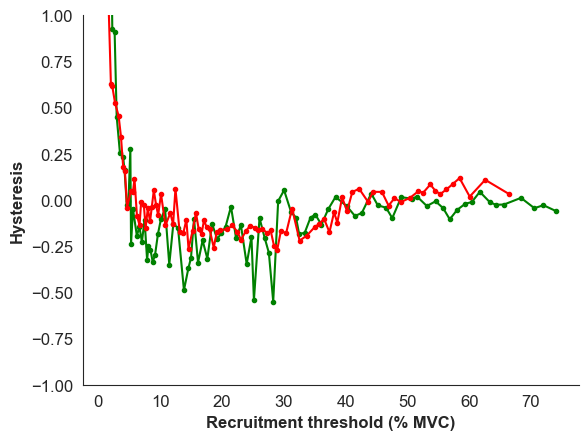

In [4]:
sns.set_style("white")
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12

def process_data(file_path):
    df = pd.read_csv(file_path)
    df = df.dropna(how='all')
    df['hysteresis'] = df.iloc[:, 1] / df.iloc[:, 0] - 1
    df['zscore'] = zscore(df['hysteresis'])
    return df[df['zscore'].abs() <= 3] 

df1 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S1.csv')
df2 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S2.csv')
df3 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S3.csv')
df4 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S4.csv')
df5 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S5_.csv')
df6 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S6.csv')
df7 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S7.csv')
df8 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S8.csv')

df11 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S1KE.csv')
df22= process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S2KE.csv')
df33 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S3KE.csv')
df44 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S4KE.csv')
df55 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S5KE.csv')
df66 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S6KE.csv')
df77 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S7KE.csv')
df88 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S8KE.csv')

all_values_hysteresis=np.concatenate([df["hysteresis"] for df in [df1, df2, df3, df4, df5, df6, df7, df8]])
all_values_recr= np.concatenate([df.iloc[:, 0] for df in [df1, df2, df3, df4, df5, df6, df7, df8]])

all_values_hysteresisKE=np.concatenate([df["hysteresis"] for df in [df11, df22, df33, df44, df55, df66, df77, df88]])
all_values_recrKE= np.concatenate([df.iloc[:, 0] for df in [df11, df22, df33, df44, df55, df66, df77, df88]])

combined_df = pd.DataFrame({ 'force': all_values_recr,'hysteresis': all_values_hysteresis})
sorted_df = combined_df.sort_values(by='force')

combined_dKE = pd.DataFrame({ 'force': all_values_recrKE,'hysteresis': all_values_hysteresisKE})
sorted_dfKE = combined_dKE.sort_values(by='force')

vals=np.array(sorted_df['hysteresis'])
vals_force=np.array(sorted_df['force'])

valsKE =np.array(sorted_dfKE['hysteresis'])
vals_forceKE =np.array(sorted_dfKE['force'])

d=10

binned_hyst = [np.mean(vals[i:i+d]) for i in range(0, len(vals), d) if i+d <= len(vals)]
binned_hyst_var = [np.var(vals[i:i+d]) for i in range(0, len(vals), d) if i+d <= len(vals)]

binned_force = [np.mean(vals_force[i:i+d]) for i in range(0, len(vals_force), d) if i+d <= len(vals_force)]


binned_hystKE = [np.mean(valsKE[i:i+d]) for i in range(0, len(valsKE), d) if i+d <= len(valsKE)]
binned_hyst_varKE = [np.var(valsKE[i:i+d]) for i in range(0, len(valsKE), d) if i+d <= len(valsKE)]

binned_forceKE = [np.mean(vals_forceKE[i:i+d]) for i in range(0, len(vals_forceKE), d) if i+d <= len(vals_forceKE)]

# plt.scatter(df1.iloc[:, 0], df1['hysteresis'], alpha=0.3, label='S1')
# plt.scatter(df2.iloc[:, 0], df2['hysteresis'], alpha=0.3, label='S2')
# plt.scatter(df3.iloc[:, 0], df3['hysteresis'], alpha=0.3, label='S3')
# plt.scatter(df4.iloc[:, 0], df4['hysteresis'], alpha=0.3, label='S4')
# plt.scatter(df5.iloc[:, 0], df5['hysteresis'], alpha=0.3, label='S5')
# plt.scatter(df6.iloc[:, 0], df6['hysteresis'], alpha=0.3, label='S6')
# plt.scatter(df7.iloc[:, 0], df7['hysteresis'], alpha=0.3, label='S7')
# plt.scatter(df8.iloc[:, 0], df8['hysteresis'], alpha=0.3, label='S8')

plt.plot(binned_force,binned_hyst, '.-', color='green')#label='Evolving Mean')
plt.plot(binned_forceKE,binned_hystKE, '.-', color='red')#label='Evolving Mean')


#######
plt.ylim(-1, 1)
# plt.title('Experimental Hysteresis', fontsize=16, fontweight='bold')
plt.xlabel('Recruitment threshold (% MVC)', fontsize=12, fontweight='bold')
plt.ylabel('Hysteresis', fontsize=12, fontweight='bold')

# plt.ylabel('Force(Derecruitment)/Force(Recruitment) - 1', fontsize=12, fontweight='bold')
# plt.legend()

sns.despine()

plt.show()


(array([11., 31., 17., 20.,  3.,  0.,  1.,  1.,  1.,  2.,  0.,  0.,  0.,
         0.,  1.,  0.,  0.,  0.,  0.,  1.]),
 array([-0.27261807, -0.17596732, -0.07931658,  0.01733417,  0.11398492,
         0.21063566,  0.30728641,  0.40393716,  0.5005879 ,  0.59723865,
         0.6938894 ,  0.79054014,  0.88719089,  0.98384164,  1.08049238,
         1.17714313,  1.27379388,  1.37044463,  1.46709537,  1.56374612,
         1.66039687]),
 <BarContainer object of 20 artists>)

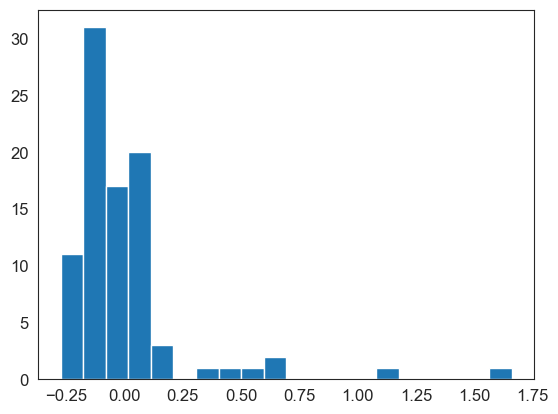

In [28]:
filtered_data = [x for x in binned_hystKE if x < 20]
plt.hist(filtered_data, bins=20) 

In [29]:
np.savetxt("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/histogramVL_hysteresis.csv", filtered_data, delimiter=",")


In [13]:
all_values_hysteresis=np.concatenate([df["hysteresis"] for df in [df1, df2, df3, df4, df5, df6, df7, df8]])
all_values_recr= np.concatenate([df.iloc[:, 0] for df in [df1, df2, df3, df4, df5, df6, df7, df8]])
all_values_derecr= np.concatenate([df.iloc[:, 1] for df in [df1, df2, df3, df4, df5, df6, df7, df8]]) #not necessary

combined_df = pd.DataFrame({ 'force': all_values_recr,'forceder': all_values_derecr,'hysteresis': all_values_hysteresis})
sorted_df = combined_df.sort_values(by='force')

vals=np.array(sorted_df['hysteresis'])
vals_force=np.array(sorted_df['force'])
vals_forceder=np.array(sorted_df['forceder'])

d=10

binned_hyst = [np.mean(vals[i:i+d]) for i in range(0, len(vals), d) if i+d <= len(vals)]
binned_hyst_var = [np.var(vals[i:i+d]) for i in range(0, len(vals), d) if i+d <= len(vals)]
binned_force = [np.mean(vals_force[i:i+d]) for i in range(0, len(vals_force), d) if i+d <= len(vals_force)]
binned_forceder = [np.mean(vals_forceder[i:i+d]) for i in range(0, len(vals_forceder), d) if i+d <= len(vals_forceder)]

In [16]:
np.savetxt("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/recr_forceVL.csv", binned_force, delimiter=",")
np.savetxt("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/hysteresisVL.csv", binned_hyst, delimiter=",")
np.savetxt("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/derecr_forceVL.csv", binned_forceder, delimiter=",")


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


(-0.9, 0.9)

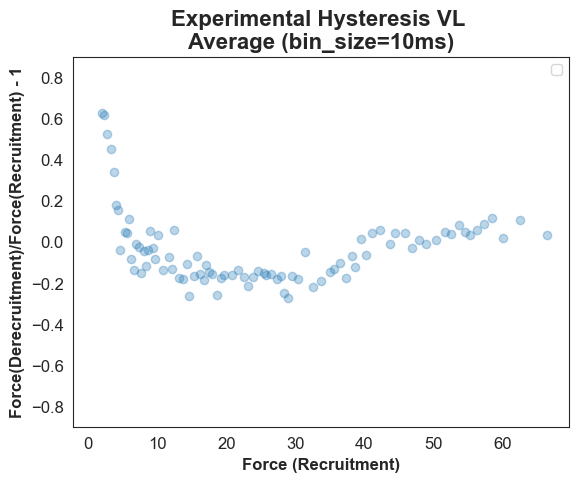

In [15]:
sns.set_style("white")

plt.rcParams['axes.labelsize'] = 14
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12


plt.scatter(binned_force,binned_hyst,alpha=0.3)

plt.title('Experimental Hysteresis VL \nAverage (bin_size=10ms)', fontsize=16, fontweight='bold')
plt.xlabel('Force (Recruitment)', fontsize=12, fontweight='bold')
plt.ylabel('Force(Derecruitment)/Force(Recruitment) - 1', fontsize=12, fontweight='bold')
plt.legend()
plt.ylim(-0.9,0.9)